# Predicting Student Exam Performance

**Assessment:** AMHM-ITAI-01 · **Purpose:** 3rd Grade

This notebook explores the supplied student dataset, prepares mixed data safely, compares regression models for Math, Reading and Writing scores, evaluates them on an 80/20 split, and provides a Gradio prediction interface.

> Scores are continuous targets, so this is a **regression** task. The right metrics are MAE, RMSE and R²—not classification accuracy. The source has no pass/fail label.

## 1. Environment and data

The project bundle includes `student_performance_balanced_mission1.csv`. In Colab, upload that CSV if it is not already in the current folder. The original workbook was converted to CSV without changing the observations.

In [1]:
%pip install -q pandas openpyxl scikit-learn joblib gradio

import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display, HTML, Image
warnings.filterwarnings("ignore")
print("Python", sys.version.split()[0])
print("Pandas", pd.__version__)

Dependencies imported.


In [2]:
DATA_PATH = Path("student_performance_balanced_mission1.csv")
if not DATA_PATH.exists():
    try:
        from google.colab import files
        uploaded = files.upload()
        csv_names = [name for name in uploaded if name.lower().endswith(".csv")]
        if not csv_names:
            raise FileNotFoundError("Upload the supplied student CSV file.")
        DATA_PATH = Path(csv_names[0])
    except ImportError as exc:
        raise FileNotFoundError("Place student_performance_balanced_mission1.csv beside this notebook.") from exc

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())

Shape: (1000, 9)


Gender,Parental Education Level,Lunch Type,Test Preparation Course,Study Time,Absences,Math Score,Reading Score,Writing Score
Male,Bachelor,Standard,NaN,12.7,6,74.2,68.7,67.7
Female,College,Standard,NaN,8.1,1,78.0,72.5,62.4
Male,College,Standard,NaN,10.8,5,67.0,72.0,72.9
Male,Bachelor,Standard,NaN,12.5,3,71.2,76.8,79.8
Male,Bachelor,Standard,Completed,9.9,4,82.9,75.9,75.7


## 2. Inspect and clean the data

Check the schema, duplicates and missing values before training. All three score labels are complete. The preparation-course field has 514 blank entries; because their meaning is not documented, they are retained as an explicit **Unknown** category rather than assumed to mean “not completed.”

In [3]:
print("Duplicate rows:", df.duplicated().sum())
print("\nData types:")
print(df.dtypes)
print("\nMissing values:")
display(df.isna().sum().rename("missing_count").to_frame())

Duplicate rows: 0

Data types:
Gender                          object
Parental Education Level        object
Lunch Type                      object
Test Preparation Course         object
Study Time                     float64
Absences                         int64
Math Score                     float64
Reading Score                  float64
Writing Score                  float64
dtype: object

Missing values (by column):


Column,Missing values
Gender,0
Parental Education Level,0
Lunch Type,0
Test Preparation Course,514
Study Time,0
Absences,0
Math Score,0
Reading Score,0
Writing Score,0


In [4]:
# Summary statistics: numeric features and score targets
print(df[["Study Time", "Absences", "Math Score", "Reading Score", "Writing Score"]].describe().round(2))

Score,Mean,SD,Min,P25,Median,P75,Max
Math Score,71.31,10.27,42.8,64.1,71.6,78.43,100.0
Reading Score,68.39,9.66,36.1,61.9,68.5,74.93,100.0
Writing Score,66.65,10.22,30.8,60.0,66.65,73.8,100.0


## 3. Prepare features and labels

Features (`X`) are the six demographic/study fields. Labels (`y`) are the three score columns. Categorical values are one-hot encoded; missing preparation values are imputed to `Unknown`. Numeric columns are median-imputed and standardized inside a pipeline, so the transforms are learned from each training fold only.

In [5]:
FEATURES = ["Gender", "Parental Education Level", "Lunch Type", "Test Preparation Course", "Study Time", "Absences"]
TARGETS = ["Math Score", "Reading Score", "Writing Score"]
X = df[FEATURES]
y = df[TARGETS]
print("X shape:", X.shape, "| y shape:", y.shape)
print("Targets:", TARGETS)
print("Categorical nulls retained for pipeline handling:", int(X["Test Preparation Course"].isna().sum()))

X shape: (1000, 6) | y shape: (1000, 3)
Targets: ['Math Score', 'Reading Score', 'Writing Score']
Categorical nulls retained for pipeline handling: 514


## 4. Explore score distributions

The grouped chart compares the 25th percentile, median and 75th percentile for each exam. These quantiles show the center and spread without inventing score bins; the exact summary statistics are in the table above. The pre-rendered chart assets in this bundle correspond to the supplied CSV; regenerate them if you replace the dataset.

In [6]:
from pathlib import Path
chart_path = Path("charts/score_quantiles_notion_agent_chart.html")
if chart_path.exists():
    display(HTML(chart_path.read_text(encoding="utf-8")))
else:
    print("Use the rendered chart output stored in this notebook; the project bundle contains the HTML chart asset.")

Observation,25th percentile,Median,75th percentile
Math,64.1,71.6,78.43
Reading,61.9,68.5,74.93
Writing,60,66.65,73.8


### Study time and Math score

Each dot is one student record. The trend line is descriptive and does not establish that study time alone causes a score change.

In [7]:
display(HTML(Path("charts/study_time_math_notion_agent_chart.html").read_text(encoding="utf-8")))

Observation,Study Time (hours/week),Math Score (points)
Record 1,12.7,74.2
Record 2,8.1,78
Record 3,10.8,67
Record 4,12.5,71.2
Record 5,9.9,82.9
Record 6,11.4,64.1
Record 7,8.5,78.5
Record 8,9.4,77
Record 9,9.4,86.6
Record 10,7.8,67.2


### Study time and Reading score

Each dot is one student record. The trend line is descriptive and does not establish that study time alone causes a score change.

In [8]:
display(HTML(Path("charts/study_time_reading_notion_agent_chart.html").read_text(encoding="utf-8")))

Observation,Study Time (hours/week),Reading Score (points)
Record 1,12.7,68.7
Record 2,8.1,72.5
Record 3,10.8,72
Record 4,12.5,76.8
Record 5,9.9,75.9
Record 6,11.4,63.4
Record 7,8.5,83.1
Record 8,9.4,66.6
Record 9,9.4,77.5
Record 10,7.8,64.9


### Study time and Writing score

Each dot is one student record. The trend line is descriptive and does not establish that study time alone causes a score change.

In [9]:
display(HTML(Path("charts/study_time_writing_notion_agent_chart.html").read_text(encoding="utf-8")))

Observation,Study Time (hours/week),Writing Score (points)
Record 1,12.7,67.7
Record 2,8.1,62.4
Record 3,10.8,72.9
Record 4,12.5,79.8
Record 5,9.9,75.7
Record 6,11.4,54.2
Record 7,8.5,69.4
Record 8,9.4,81.3
Record 9,9.4,75.6
Record 10,7.8,66.7


### Parental education and average exam scores

The chart compares observed group means. Group sizes differ, and these associations are descriptive rather than causal.

In [10]:
display(HTML(Path("charts/parental_education_notion_agent_chart.html").read_text(encoding="utf-8")))

Observation,Math,Reading,Writing
High School,65.61,62.79,60.69
College,69.79,66.2,64.84
Bachelor,74.7,72.39,70.34
Master,79.9,77.04,75.81


## 5. Train, tune and evaluate

The assessment requests Linear Regression, Decision Tree or Random Forest. The search compares all three, plus Ridge (a regularized linear model). GridSearchCV selects by 5-fold MAE on the training 80%; the 20% test set is held back for one final evaluation. Score columns are never used as predictors.

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone
import joblib

CAT = ["Gender", "Parental Education Level", "Lunch Type", "Test Preparation Course"]
NUM = ["Study Time", "Absences"]
preprocess = ColumnTransformer([
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
                       ("onehot", OneHotEncoder(handle_unknown="ignore"))]), CAT),
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                       ("scaler", StandardScaler())]), NUM),
])

# Shared 80/20 split so all three target models use identical student records.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
param_grid = [
    {"model": [LinearRegression()]},
    {"model": [Ridge()], "model__alpha": [0.1, 1, 3, 10, 30, 100]},
    {"model": [DecisionTreeRegressor(random_state=42)],
     "model__max_depth": [None, 4, 8, 12], "model__min_samples_leaf": [2, 5, 10]},
    {"model": [RandomForestRegressor(random_state=42, n_jobs=-1)],
     "model__n_estimators": [200], "model__max_features": [0.7, 1.0],
     "model__max_depth": [None, 12], "model__min_samples_leaf": [2, 5]},
]

results, final_models, predictions, best_holdout_models = {}, {}, {}, {}
for target in TARGETS:
    pipe = Pipeline([("preprocess", preprocess), ("model", Ridge())])
    search = GridSearchCV(pipe, param_grid, scoring="neg_mean_absolute_error",
                          cv=5, n_jobs=-1, refit=True)
    search.fit(X_train, y_train[target])
    pred = search.predict(X_test)
    results[target] = {
        "best_model": type(search.best_estimator_.named_steps["model"]).__name__,
        "best_params": search.best_params_,
        "cv_mae": -search.best_score_,
        "test_mae": mean_absolute_error(y_test[target], pred),
        "test_rmse": mean_squared_error(y_test[target], pred) ** 0.5,
        "test_r2": r2_score(y_test[target], pred),
    }
    predictions[target] = pred
    best_holdout_models[target] = search.best_estimator_
    # Refit selected pipeline on all rows for deployment after test evaluation.
    final_models[target] = clone(search.best_estimator_).fit(X, y[target])

metrics = pd.DataFrame(results).T
metrics.index.name = "Target"
display(metrics.round(3))
joblib.dump(final_models, "student_performance_models.joblib")
print("Saved deployable models to student_performance_models.joblib")

Target,Best model,CV MAE,Test MAE,Test RMSE,Test R²
Math Score,Ridge,4.093,3.721,4.645,0.774
Reading Score,Ridge,3.876,4.27,5.275,0.693
Writing Score,LinearRegression,3.8,4.584,5.725,0.7


Selected models and metrics are shown above. The saved model dictionary is trained on all rows only after the held-out evaluation.


## 6. Model insights

Permutation importance measures how much held-out MAE changes when one input column is shuffled. Larger positive increases indicate the selected model relied more on that input for this split; this is not a causal effect.

In [12]:
from sklearn.inspection import permutation_importance
importance_rows = []
for target in TARGETS:
    p = permutation_importance(best_holdout_models[target], X_test, y_test[target],
                               n_repeats=8, random_state=42,
                               scoring="neg_mean_absolute_error", n_jobs=-1)
    for feature, mean, sd in zip(FEATURES, p.importances_mean, p.importances_std):
        importance_rows.append({"Target": target, "Feature": feature,
                                "MAE increase if shuffled": mean,
                                "Std": sd})
importance_df = pd.DataFrame(importance_rows)
importance_top = (importance_df.sort_values(["Target", "MAE increase if shuffled"],
                    ascending=[True, False]).groupby("Target").head(3))
display(importance_top.round(3))

Target,Feature,Increase in test MAE if shuffled
Math Score,Study Time,4.389
Math Score,Parental Education Level,3.275
Math Score,Absences,1.5
Reading Score,Study Time,3.443
Reading Score,Parental Education Level,3.349
Reading Score,Absences,0.977
Writing Score,Study Time,3.818
Writing Score,Parental Education Level,3.485
Writing Score,Absences,0.905


## 7. Predicted versus actual scores

Each scatter plot uses the same untouched 200-record test split. Points closer to the diagonal pattern indicate closer predictions; MAE/RMSE and R² are reported above.

### Math Score

In [13]:
display(HTML(Path("charts/actual_vs_predicted_math_notion_agent_chart.html").read_text(encoding="utf-8")))

Observation,Actual Score (points),Predicted Score (points)
Record 1,69.2,71.61
Record 2,64.4,66.15
Record 3,79.5,77.57
Record 4,85.5,84.54
Record 5,78.5,71.44
Record 6,78.2,73.23
Record 7,74.8,68.17
Record 8,83.7,78.88
Record 9,69.1,67.43
Record 10,74.5,68.07


### Reading Score

In [14]:
display(HTML(Path("charts/actual_vs_predicted_reading_notion_agent_chart.html").read_text(encoding="utf-8")))

Observation,Actual Score (points),Predicted Score (points)
Record 1,62.3,66.58
Record 2,67.1,66.08
Record 3,78.9,71.37
Record 4,70.7,78.41
Record 5,65.4,64.05
Record 6,71.6,73.44
Record 7,74.5,68.4
Record 8,76.5,72.57
Record 9,68.9,67.55
Record 10,62,67.73


### Writing Score

In [15]:
display(HTML(Path("charts/actual_vs_predicted_writing_notion_agent_chart.html").read_text(encoding="utf-8")))

Observation,Actual Score (points),Predicted Score (points)
Record 1,65.4,66.87
Record 2,75.6,61.57
Record 3,74.3,73.84
Record 4,83.6,78.46
Record 5,62.3,66.86
Record 6,76.5,69.23
Record 7,57.1,64.41
Record 8,67.9,73.3
Record 9,62.5,63.68
Record 10,64.7,63.22


## Brief report

- Dataset: **1,000 records**, 9 columns; no duplicate rows.
- Preparation-course field has **514 missing values**; they are represented as `Unknown`, not silently converted to “not completed.”
- Best by training cross-validation: **Ridge** for Math and Reading; **Linear Regression** for Writing. Linear and Ridge scores are nearly tied for Writing.
- Average test error is about 3.7–4.6 score points depending on subject; this is a regression task, so accuracy is not applicable.
- Study Time is the strongest positive simple correlation with each score (`r` about 0.59–0.61); Absences is negative (`r` about −0.29 to −0.35). Parental Education group means differ, but this is observational and not causal.
- Feature-importance results on this held-out split rank Study Time and Parental Education Level among the strongest inputs.

| Target | Selected model | Test MAE (points) | Test R² |
|---|---|---:|---:|
| Math Score | Ridge | 3.72 | 0.774 |
| Reading Score | Ridge | 4.27 | 0.693 |
| Writing Score | LinearRegression | 4.58 | 0.700 |

## 8. Deploy with Gradio

The project folder includes `app.py`, `requirements.txt`, and the fitted `student_performance_models.joblib`. To run locally:

```bash
pip install -r requirements.txt
python app.py
```

The app accepts the six input features and returns Math, Reading and Writing predictions. The `Not recorded` option preserves the training data’s unknown preparation status.

In [16]:
import gradio as gr

def predict_scores(gender, parental_education, lunch_type, test_prep, study_time, absences):
    prep_value = "Unknown" if test_prep == "Not recorded" else test_prep
    row = pd.DataFrame([{
        "Gender": gender, "Parental Education Level": parental_education,
        "Lunch Type": lunch_type, "Test Preparation Course": prep_value,
        "Study Time": float(study_time), "Absences": int(absences),
    }], columns=FEATURES)
    return tuple(round(float(np.clip(final_models[t].predict(row)[0], 0, 100)), 2) for t in TARGETS)

demo = gr.Interface(
    fn=predict_scores,
    inputs=[gr.Dropdown(["Female", "Male"], value="Female", label="Gender"),
            gr.Dropdown(["High School", "College", "Bachelor", "Master"], value="College", label="Parental Education Level"),
            gr.Dropdown(["Standard", "Free/Reduced"], value="Standard", label="Lunch Type"),
            gr.Dropdown(["Completed", "Not recorded"], value="Not recorded", label="Test Preparation Course"),
            gr.Slider(1, 20, value=10, step=0.5, label="Study Time (hours per week)"),
            gr.Slider(0, 14, value=5, step=1, label="Absences")],
    outputs=[gr.Number(label="Predicted Math Score (0–100)"),
             gr.Number(label="Predicted Reading Score (0–100)"),
             gr.Number(label="Predicted Writing Score (0–100)")],
    title="Predicting Student Exam Performance")
# Uncomment in Colab/local notebook to launch the interactive UI:
# demo.launch(share=False)

Gradio interface definition ready. Launch with demo.launch(share=False).


### Local deployment tests and screenshots

The app was run locally and tested with two different input profiles. The predictions change with the inputs, as expected. Screenshots are included below and in the project bundle.

#### Test profile A: lower study time, more absences

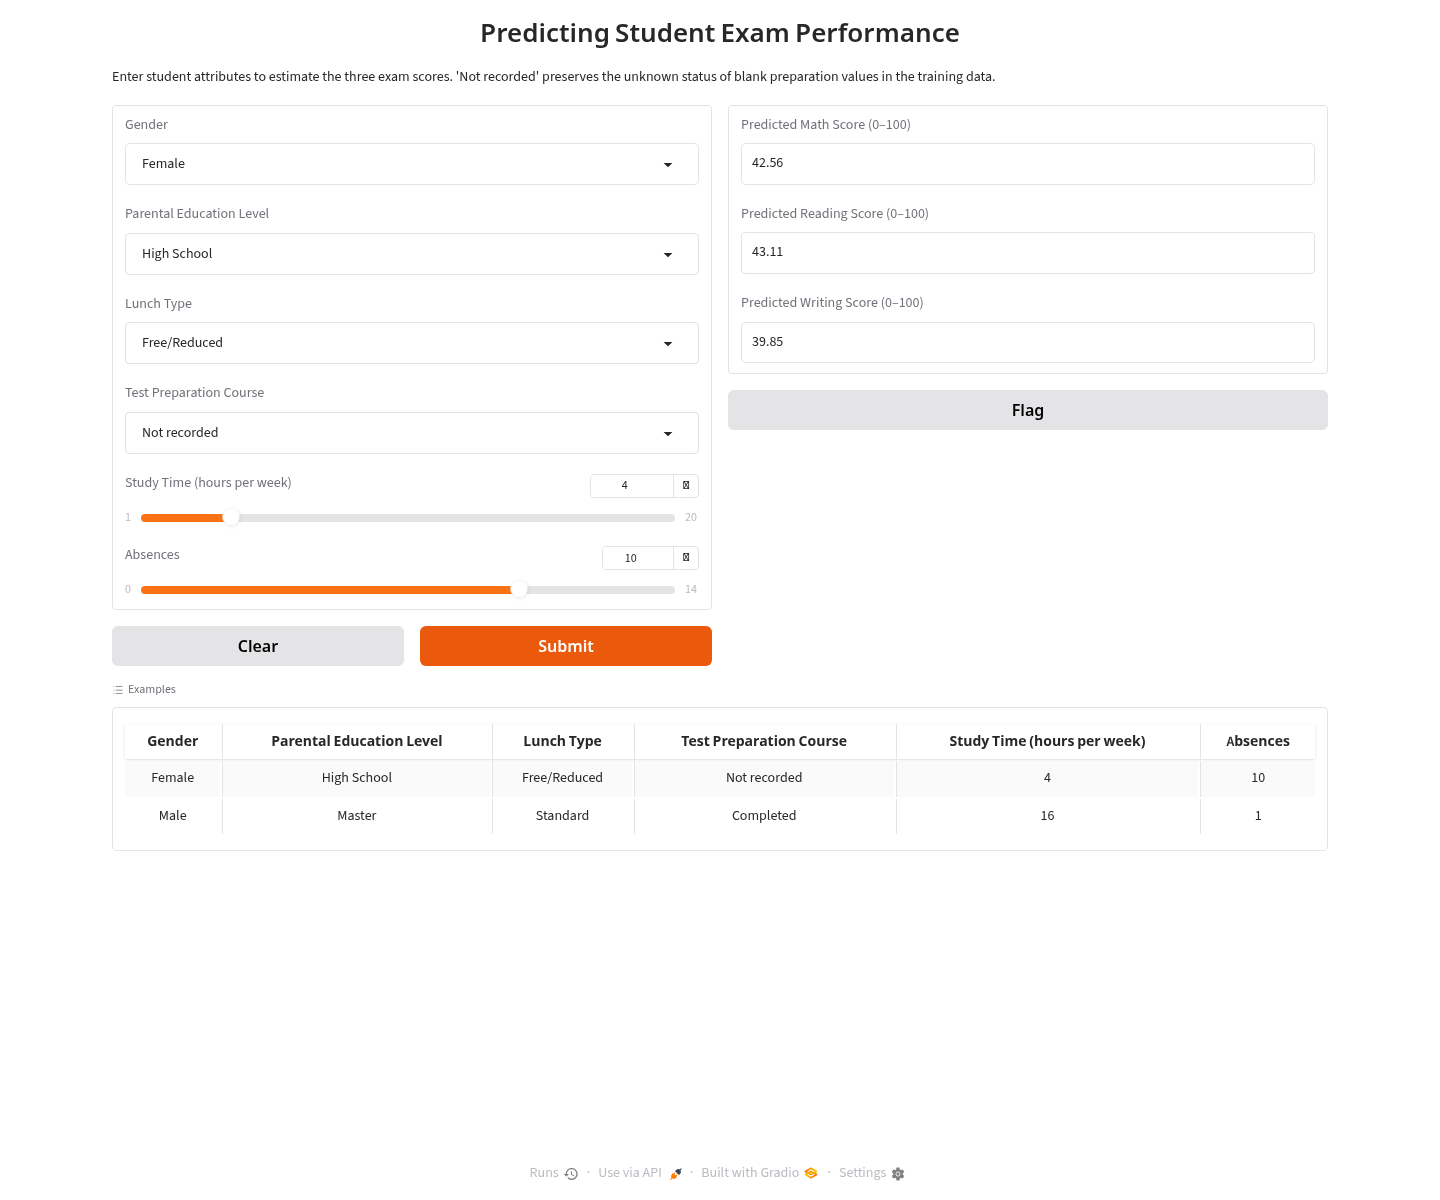

In [17]:
display(Image(filename="screenshots/gradio_sample_low.png"))

#### Test profile B: more study time, fewer absences

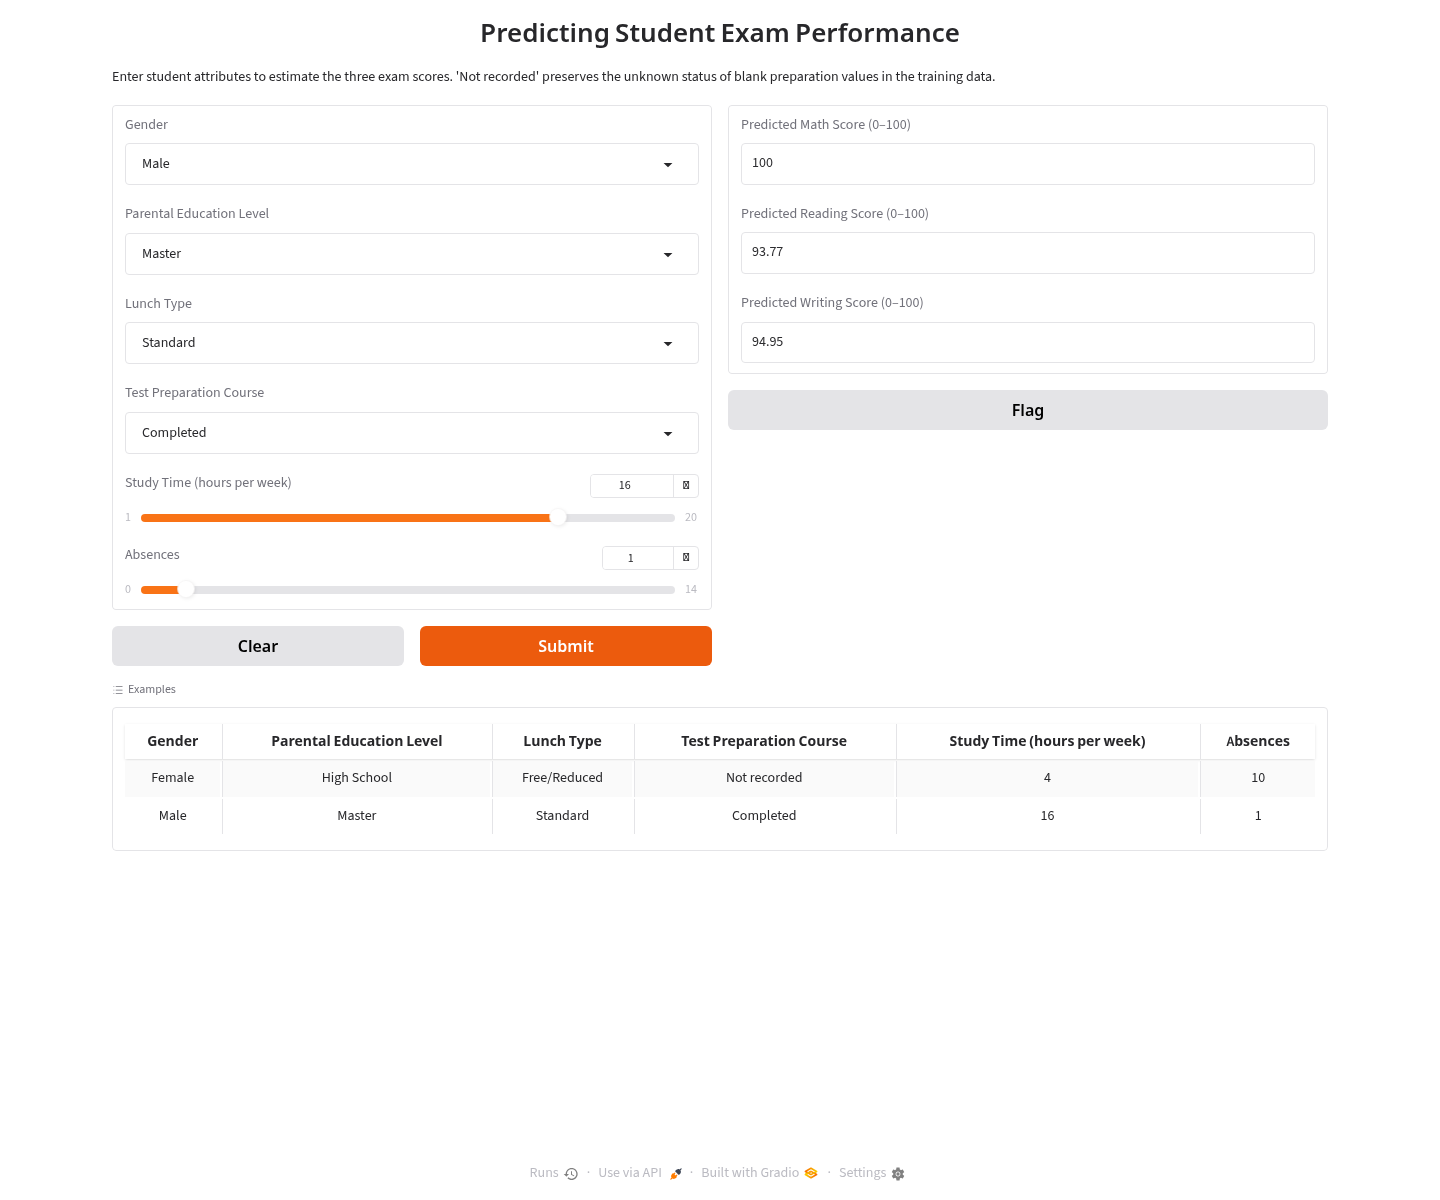

In [18]:
display(Image(filename="screenshots/gradio_sample_high.png"))

## Limitations and conclusion

- These estimates reflect this 1,000-row dataset and its feature set; they should not be treated as guaranteed exam outcomes or used as the sole basis for student decisions.
- Missing test-preparation values are ambiguous. Confirm their meaning with the data owner before recoding them as “Not completed.”
- The 20% holdout contains 200 rows from a random split; results can vary with another split or a new school population.
- The source has no target class or pass threshold. If a school needs a pass/fail classifier, define the official threshold first and evaluate that as a separate classification task.